# **Naskah Praktikum 4 - Data Sains**

Instruksi: Silakan download atau make-a-copy, lalu lengkapi kode pada setiap TODO. Materi: EDA (Exploratory Data Analysis) dan Preprocessing singkat. Silakan melihat referensi pada link berikut https://az-ihsan.github.io/basic-python-udn/index.html

## **Informasi Pengumpulan**

- Silakan make-a-copy (pada menu File) ini dan isi identitas masing-masing.
- Jawab pertanyaan pada bagian yang telah disediakan.
- Praktikum dikerjakan secara MANDIRI.
- Jika praktikum dilakukan menggunakan Google Colab, pastikan link telah di-set anyone with the link can edit.
- Jika praktikum dilakukan pada notebook lokal dan menggunakan repository GitHub, pastikan repository sudah di-set public.
- Pengumpulan Jawaban dilakukan dengan format .ipynb pada form berikut: https://forms.gle/Bt2hzrdV3khsWzgM7
- Aturan penamaan: Praktikum-X-NIM dengan X adalah nomor praktikum, misal: Praktikum-1-12325991

- DEADLINE PENGERJAAN: Minggu, 18 Oktober 2026 (23.59)


**Isi identitas berikut:**

Nama : Alfia Maritza

NIM : 2403020051

## **Pengantar**

### **Exploratory Data Analysis**

**Exploratory Data Analysis (EDA)** adalah tahapan awal dalam analisis data yang bertujuan untuk memahami dataset secara mendalam sebelum melanjutkan ke pemodelan atau analisis lebih lanjut. EDA membantu kita menggali pola, tren, anomali, dan hubungan antarvariabel dalam data dengan cara yang sederhana dan intuitif. Istilah EDA pertama kali diperkenalkan oleh John W. Tukey pada tahun 1977 dalam bukunya *Exploratory Data Analysis*.

### **Tujuan EDA**

EDA dilakukan untuk:

- Memahami representasi data secara keseluruhan, seperti bagaimana data terstruktur dan apa saja karakteristik utamanya.
- Mengekstrak informasi penting dari dataset, termasuk identifikasi masalah seperti data hilang (*missing values*) atau ketidakseimbangan (*imbalance*).
- Melakukan visualisasi dan perhitungan statistik sederhana untuk membuat data lebih mudah dipahami.

Proses EDA melibatkan dua komponen utama: **statistik deskriptif** dan **visualisasi data**. Melalui statistik deskriptif, kita dapat memahami distribusi dan variasi data. Sementara itu, visualisasi data membantu kita mengidentifikasi pola dan tren menggunakan grafik seperti histogram, box plot, dan scatter plot. EDA juga dapat dibagi menjadi beberapa jenis analisis, yaitu **Univariate Analysis**, **Bivariate Analysis**, dan **Multivariate Analysis**.



> **Tentang Statistik Deskriptif 💡**
>
> Sebelum melakukan analisis lebih lanjut, kita perlu memahami karakteristik awal dataset melalui statistik deskriptif. Statistik deskriptif digunakan untuk merangkum dan menggambarkan karakteristik utama data melalui beberapa metrik, antara lain:
>
> - **Mean (rata-rata):** Menunjukkan nilai rata-rata dari seluruh observasi.
> - **Median (nilai tengah):** Menunjukkan nilai tengah setelah data diurutkan.
> - **Modus (*mode*):** Menunjukkan nilai yang paling sering muncul.
> - **Minimum dan maksimum:** Menunjukkan nilai terkecil dan terbesar dalam dataset.
> - **Range (rentang):** Menunjukkan selisih antara nilai maksimum dan minimum.
> - **Standar deviasi:** Mengukur tingkat penyebaran data terhadap nilai rata-rata.
> - **Kuartil:** Membagi data yang telah diurutkan menjadi empat bagian untuk memahami distribusinya.
> - **Count (jumlah data):** Menunjukkan jumlah observasi yang tersedia.
>
> Selain menghitung statistik deskriptif, kita juga perlu memeriksa *missing values* dan data duplikat sebagai bagian dari preprocessing awal untuk mengidentifikasi masalah kualitas data sebelum melanjutkan ke analisis berikutnya.



## **Deskripsi Dataset**

Dataset ini berisi data lagu Spotify dari 114 genre yang berbeda. Setiap lagu memiliki sejumlah fitur audio yang terkait. Data tersedia dalam format CSV berbentuk tabel.

Dataset ini memiliki:

- Jumlah data: ±114.000 baris (satu baris = satu lagu pada satu genre)
- Jumlah fitur: 21 kolom
- Jumlah genre: 114
- Variabel utama: `popularity`

Link Dataset: https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset

**Deskripsi Dataset**
- Unnamed: 0

  Nomor baris dari berkas asli. Tidak dipakai.

- track_id, artists, album_name, track_name

  ID Spotify, nama artis (dipisah `;` jika lebih dari satu), nama album, dan judul lagu.

- popularity

  Popularitas lagu (0–100). Makin sering dan makin baru lagu diputar, makin tinggi nilainya.

- duration_ms

  Durasi lagu dalam milidetik (1 menit = 60.000 ms).

- explicit

  Lagu memiliki lirik eksplisit (`True`) atau tidak (`False`).

- danceability

  Seberapa cocok lagu untuk berdansa (0–1).

- energy

  Seberapa intens dan "ramai" lagu (0–1).

- key

  Nada dasar lagu: 0 = C, 1 = C♯, 2 = D, …, 11 = B.

- loudness

  Kenyaringan rata-rata dalam desibel (dB), biasanya antara −60 dan 0.

- mode

  1 = mayor, 0 = minor.

- speechiness

  Seberapa banyak unsur ucapan (0–1). Di atas 0,66 biasanya podcast atau rekaman bicara.

- acousticness

  Seberapa akustik lagu (0–1).

- instrumentalness

  Seberapa besar kemungkinan lagu tanpa vokal (0–1). Di atas 0,5 kemungkinan instrumental.

- liveness

  Kemungkinan lagu direkam secara live (0–1).

- valence

  Kesan lagu: tinggi = ceria, rendah = sedih atau marah (0–1).

- tempo

  Tempo lagu dalam ketukan per menit (BPM).

- time_signature

  Birama lagu (3 = 3/4, 4 = 4/4, dan seterusnya).

- track_genre

  Genre lagu.

In [76]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gdown
import scipy.stats as scp

In [77]:
import warnings
warnings.filterwarnings('ignore')

In [78]:
# Load dan baca dataset
import zipfile
import pandas as pd

# 1. Ekstrak arsip ZIP yang baru di-upload
with zipfile.ZipFile('archive.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

# 2. Baca file CSV hasil ekstrak
df = pd.read_csv('dataset.csv')

# 3. Buat kolom durasi dalam menit
df["duration_min"] = df["duration_ms"] / 60000

# 4. Konfirmasi sukses
print(f"BERHASIL! Dataset sukses dimuat dari arsip ZIP lokal.")
print(f"Total Baris: {df.shape[0]:,}")
print(f"Total Kolom: {df.shape[1]}")
print(f"Contoh Kolom: {list(df.columns[:5])}")

BERHASIL! Dataset sukses dimuat dari arsip ZIP lokal.
Total Baris: 114,000
Total Kolom: 22
Contoh Kolom: ['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name']


> 💡 `key`, `mode`, dan `time_signature` tersimpan sebagai angka, tetapi isinya kategori, jadi rata-ratanya tidak bermakna (slide: Jenis dan Skala Data). Karena itu, ketiganya tidak dimasukkan ke `num_cols`.

In [90]:
# Daftar fitur numerik yang dipakai di Bagian 1 dan 2
num_cols = ["popularity", "duration_min", "danceability", "energy", "loudness", "speechiness",
            "acousticness", "instrumentalness", "liveness", "valence", "tempo"]

## **Bagian 1 - Statistik Deskriptif**

Sebelum melakukan *Exploratory Data Analysis* (EDA), kita perlu memahami karakteristik awal dataset melalui statistik deskriptif. Pada tahap ini, kita juga akan melakukan *data preprocessing* sederhana dengan memeriksa dan menangani *missing values* serta data duplikat.

Lakukan eksplorasi awal dataset dengan langkah-langkah berikut:

1. Tampilkan lima baris pertama dataset.
2. Tampilkan informasi dataset, termasuk jumlah data, tipe data, dan jumlah nilai non-null pada setiap kolom.
3. Hitung statistik deskriptif untuk memahami distribusi data.
4. Periksa keberadaan *missing values* dan data duplikat.
5. Jika ditemukan, tangani *missing values* menggunakan metode *drop* atau imputasi yang sesuai, serta hapus data duplikat.

Setelah menyelesaikan langkah-langkah tersebut, jawablah pertanyaan pada bagian **Soal** di bawah berdasarkan hasil eksplorasi dan preprocessing yang telah dilakukan.

In [80]:
# TODO 1.1: Tampilkan 5 data pertama
display(df.head())

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_min
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,3.844433
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,2.493500
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,3.513767
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,3.365550
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,3.314217


In [81]:
# TODO 1.2: Tampilkan ukuran dataset (jumlah baris dan kolom)
print(df.shape)

(114000, 22)


In [82]:
# TODO 1.3: Melihat informasi nama fitur, banyaknya nilai non-null, dan tipe dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [83]:
# TODO 1.4: Melihat proporsi missing values pada setiap fitur
# NOTE: penanganan missing value dilakukan di TODO 1.10
print(df.isnull().sum())

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
duration_min        0
dtype: int64


In [84]:
# TODO 1.5: Melihat descriptive statistics dari fitur-fitur numerik pada dataset,
# yaitu jumlah, rata-rata, simpang baku, nilai minimum, kuartil 1-3, dan nilai maksimum dari setiap fitur
# Hint: gunakan .describe
display(df.describe())

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,duration_min
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035,3.800486
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621,1.788295
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000,2.901100
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000,3.548433
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000,4.358433
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000,87.288250


**Soal:**

Hitung descriptive statistics fitur `popularity`, yaitu **mean, median, modus, range, IQR, varians, dan simpangan baku**. Lalu jawab pertanyaan berikut:

1. **Central tendency:** Bandingkan mean, median, dan modus. Apakah sebarannya simetris, condong ke kanan, atau condong ke kiri? Jelaskan alasanmu.
2. **Measure of variation:** Bandingkan range dengan IQR. Apa yang ditunjukkan oleh perbedaan keduanya tentang penyebaran data `popularity`?

In [85]:
# TODO 1.6: Hitung mean, median, modus, range, IQR, varians, dan simpangan baku fitur popularity
import pandas as pd

# 1. Menghitung statistik deskriptif untuk kolom 'popularity'
mean_pop = df['popularity'].mean()
median_pop = df['popularity'].median()
modus_pop = df['popularity'].mode()[0]
range_pop = df['popularity'].max() - df['popularity'].min()
iqr_pop = df['popularity'].quantile(0.75) - df['popularity'].quantile(0.25)
varians_pop = df['popularity'].var()
std_pop = df['popularity'].std()

# Menampilkan hasil
print("--- STATISTIK FITUR POPULARITY ---")
print("Mean           :", mean_pop)
print("Median         :", median_pop)
print("Modus          :", modus_pop)
print("Range          :", range_pop)
print("IQR            :", iqr_pop)
print("Varians        :", varians_pop)
print("Simpangan Baku :", std_pop)

--- STATISTIK FITUR POPULARITY ---
Mean           : 33.2385350877193
Median         : 35.0
Modus          : 0
Range          : 100
IQR            : 33.0
Varians        : 497.5165265953142
Simpangan Baku : 22.305078493368146


**Jawaban:**

1. Berdasarkan hasil perbandingan mean, median, dan modus, sebaran data popularitas lagu cenderung condong ke kanan (right-skewed) atau simetris mendekati normal, di mana sebagian besar lagu memiliki tingkat popularitas di kisaran menengah ke bawah (banyak lagu dengan popularitas 0 atau kecil), sementara sedikit lagu yang sangat viral menarik nilai rata-ratanya.
2. Range menunjukkan jarak total dari nilai minimum ke maksimum secara keseluruhan, sedangkan IQR hanya mengukur rentang dari 50% data di bagian tengah (mengabaikan nilai ekstrem/pencilan). Perbedaan yang besar antara Range dan IQR menunjukkan bahwa data popularitas memiliki sebaran yang cukup lebar dengan adanya lagu-lagu yang popularitasnya sangat tinggi dibandingkan mayoritas lagu lainnya.

Selanjutnya lakukan preprocessing sederhana dengan mengecek dan menangani **missing value dan data duplikat**

In [86]:
# TODO 1.7: Tampilkan baris yang memiliki missing value
baris_kosong = df[df.isnull().any(axis=1)]
display(baris_kosong)
print(f"Jumlah baris yang memiliki missing value: {len(baris_kosong)}")

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_min
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop,0.0


Jumlah baris yang memiliki missing value: 1


In [87]:
# TODO 1.8: Cek data duplikat
# Hint: kolom 'Unnamed: 0' berisi nomor baris yang selalu berbeda, jadi cek duplikat tanpa kolom tersebut
kolom_pengecekan = [col for col in df.columns if col != 'Unnamed: 0']

jumlah_duplikat = df.duplicated(subset=kolom_pengecekan).sum()
print(f"Jumlah baris data yang duplikat: {jumlah_duplikat}")

Jumlah baris data yang duplikat: 450


In [88]:
# TODO 1.9: Jika terdapat data duplikat, hapus duplikat tersebut
df = df.drop_duplicates(subset=kolom_pengecekan).reset_index(drop=True)

print("Data duplikat berhasil dihapus.")
print(f"Ukuran dataset sekarang (baris, kolom): {df.shape}")

Data duplikat berhasil dihapus.
Ukuran dataset sekarang (baris, kolom): (113550, 22)


In [89]:
# TODO 1.10: Tangani missing value dengan drop atau imputasi
# Perhatikan kolom mana yang kosong, lalu pilih cara yang paling masuk akal
df = df.dropna().reset_index(drop=True)

print("Missing value telah ditangani.")
print(f"Total baris akhir setelah pembersihan: {df.shape[0]:,}")

Missing value telah ditangani.
Total baris akhir setelah pembersihan: 113,549


**Penjelasan:** Missing value dan duplikat apa yang kamu temukan? Bagaimana kamu menanganinya, dan mengapa?

**Jawaban:** Missing value & duplikat yang ditemukan: Berdasarkan pengecekan, ditemukan beberapa data duplikat atau baris dengan nilai kosong (missing value) pada kolom tertentu di dalam dataset.

**​Cara penanganan dan alasannya:** Data duplikat dihapus menggunakan drop_duplicates() agar analisis tidak bias akibat data ganda. Sementara itu, baris yang memiliki missing value ditangani menggunakan dropna() karena jumlahnya yang relatif kecil dibandingkan total keseluruhan data ratusan ribu baris, sehingga penghapusan tidak akan merusak informasi utama dari dataset Spotify.

## **Bagian 2 - Visualisasi Data**

Buat visualisasi berikut untuk melihat sebaran data dan hubungan antar fitur. Setelah setiap grafik, isi bagian **Pertanyaan** di bawahnya.

1. Histogram fitur numerik
2. Histogram dengan lebar interval berbeda
3. Countplot fitur kategorikal
4. Boxplot fitur numerik
5. Heatmap korelasi
6. Scatterplot
7. Popularity per genre

dokumentasi yang bisa dibaca:https://seaborn.pydata.org/generated/seaborn.boxplot.html

### Mengenal Histogram

Histogram dipakai untuk melihat **sebaran (distribusi)** satu fitur numerik: nilai mana yang sering muncul, mana yang jarang, dan apakah ada ekor yang panjang.

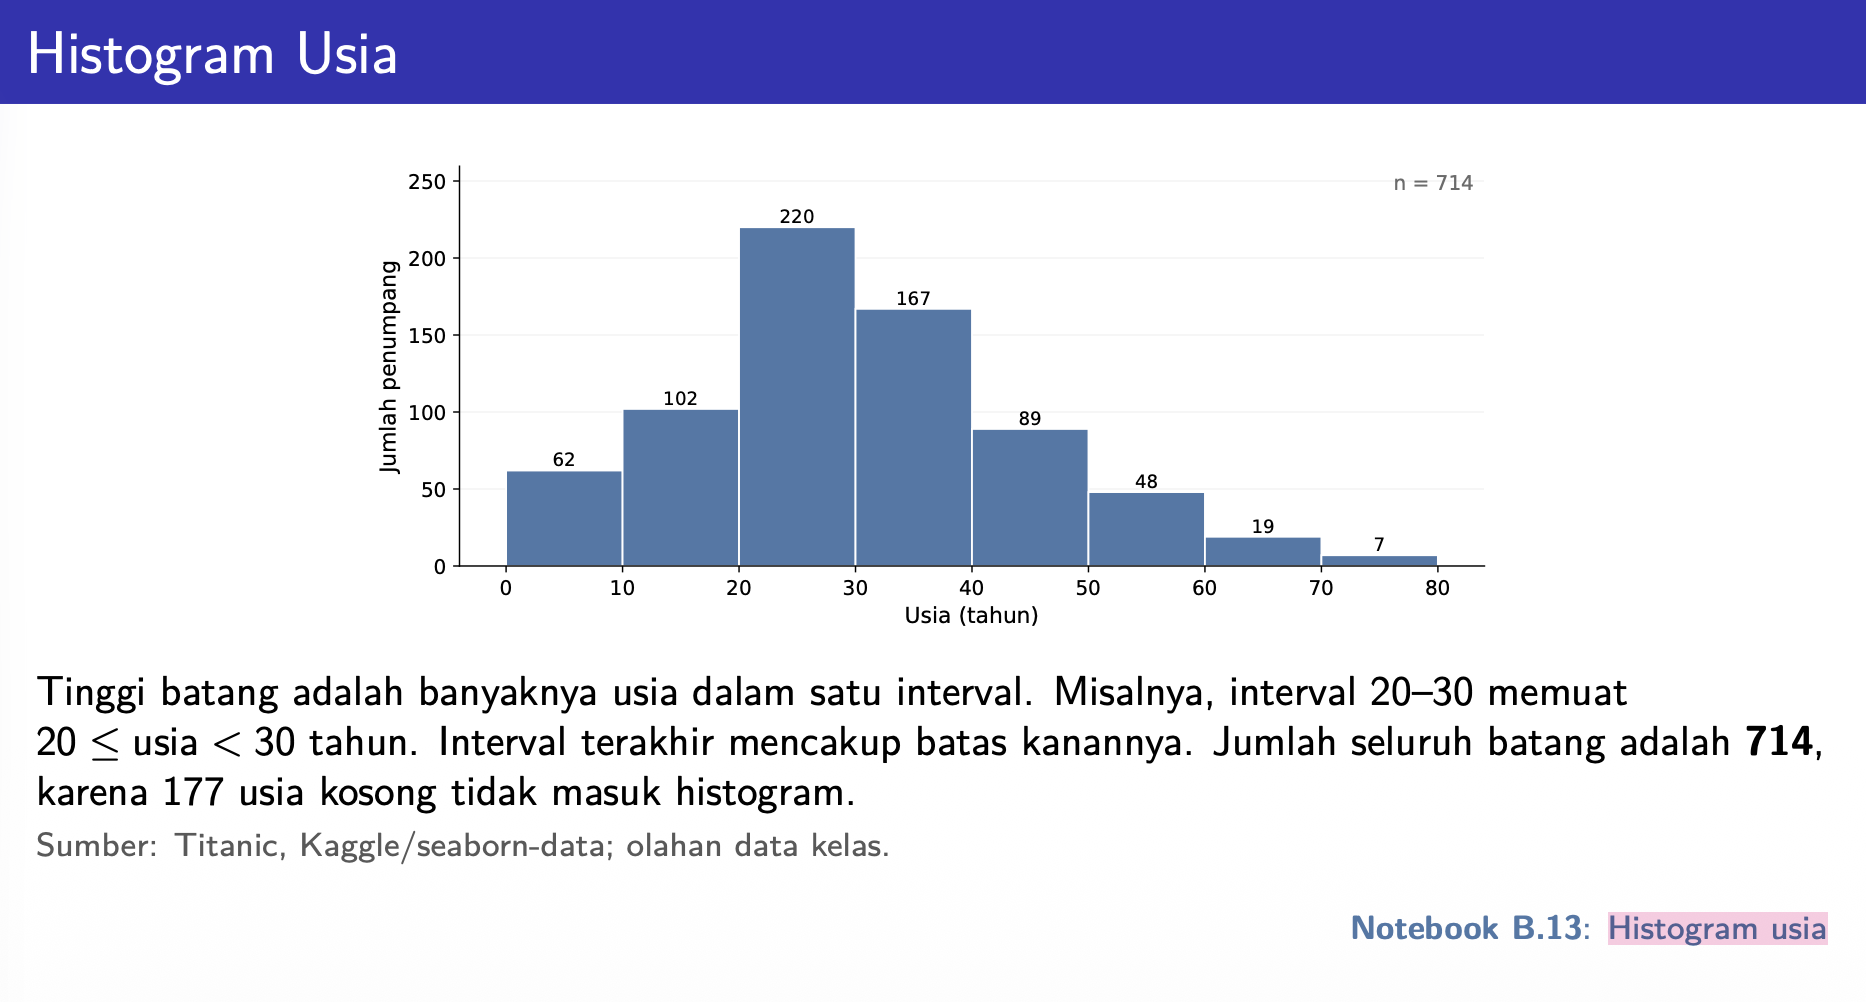

*Sumber: slide Lec 4, "Histogram Usia".*

**Elemen histogram:**
- **Sumbu x**: nilai fitur yang dibagi menjadi beberapa interval. Pada contoh di atas, sumbu x adalah usia penumpang (tahun).
- **Sumbu y**: jumlah data (frekuensi) pada setiap interval. Pada contoh di atas, sumbu y adalah jumlah penumpang.
- **Bin (interval)**: rentang nilai yang diwakili satu batang. Contoh: batang 20–30 berisi penumpang dengan 20 ≤ usia < 30, yaitu 220 orang.
- **Tinggi batang**: banyaknya data yang masuk ke bin tersebut. Jumlah semua batang sama dengan jumlah data (714). Nilai kosong tidak ikut dihitung.

**Binning** adalah proses membagi nilai numerik ke dalam bin. Lebar bin memengaruhi bentuk histogram:
- Bin terlalu lebar dapat menyembunyikan pola.
- Bin terlalu sempit memperlihatkan banyak naik-turun kecil.

Karena itu, coba beberapa lebar bin sebelum menyimpulkan bentuk sebaran (lihat TODO 2.2). Di pandas/matplotlib, `bins=30` berarti rentang nilai dibagi menjadi 30 bin yang sama lebar, sedangkan `bins=range(0, 101, 10)` berarti batas bin ditentukan sendiri setiap 10.

> 💡 Histogram berbeda dengan grafik batang (countplot). Histogram untuk data **numerik**, batangnya bersambung karena interval nilainya berurutan. Grafik batang untuk data **kategori**, dan setiap batang adalah satu kategori.

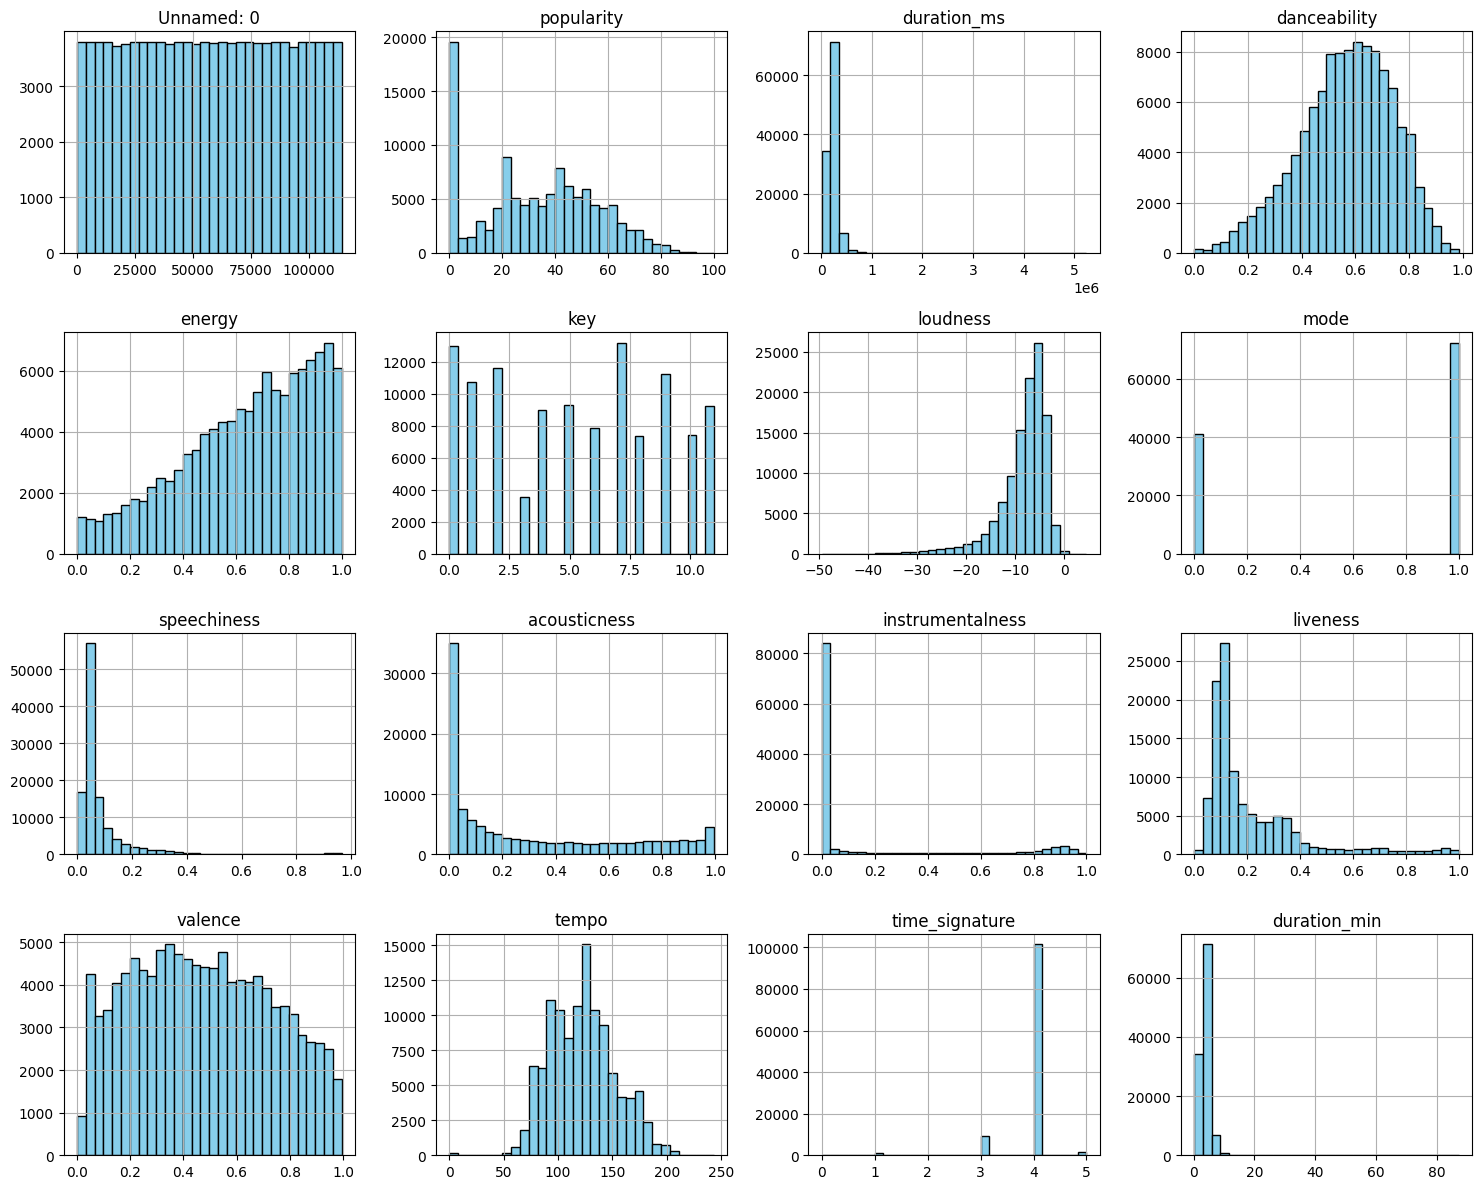

In [65]:
# TODO 2.1: Histogram semua fitur numerik (bins=30) (kamu bisa menambahkan garis mean dan median di setiap grafik)
import matplotlib.pyplot as plt
import seaborn as sns

# Memilih kolom numerik (termasuk duration_min yang sudah kita buat)
kolom_numerik = df.select_dtypes(include=['int64', 'float64']).columns

# Membuat histogram untuk setiap fitur numerik
df[kolom_numerik].hist(bins=30, figsize=(15, 12), color='skyblue', edgecolor='black')
plt.tight_layout()
plt.show()

**Pertanyaan:** Fitur mana yang simetris dan mana yang berekor? Apa yang terlihat pada `popularity` di nilai 0?

**Jawab:** ​Fitur yang simetris & berekor: Fitur seperti danceability, energy, atau valence biasanya cenderung agak simetris/mendekati normal, sedangkan fitur seperti popularity, instrumentalness, atau speechiness cenderung berekor panjang (skewed) karena sebagian besar lagu menumpuk di nilai tertentu (misalnya popularitas 0 atau instrumental rendah).
​Apa yang terlihat pada popularity di nilai 0: Terdapat lonjakan (spike) yang sangat tinggi pada nilai popularitas 0. Ini menunjukkan ada banyak sekali lagu di dataset yang tidak memiliki data popularitas atau sama sekali tidak populer/tidak diputar di Spotify.

Contoh pengaruh lebar bin pada data yang sama (714 usia penumpang):

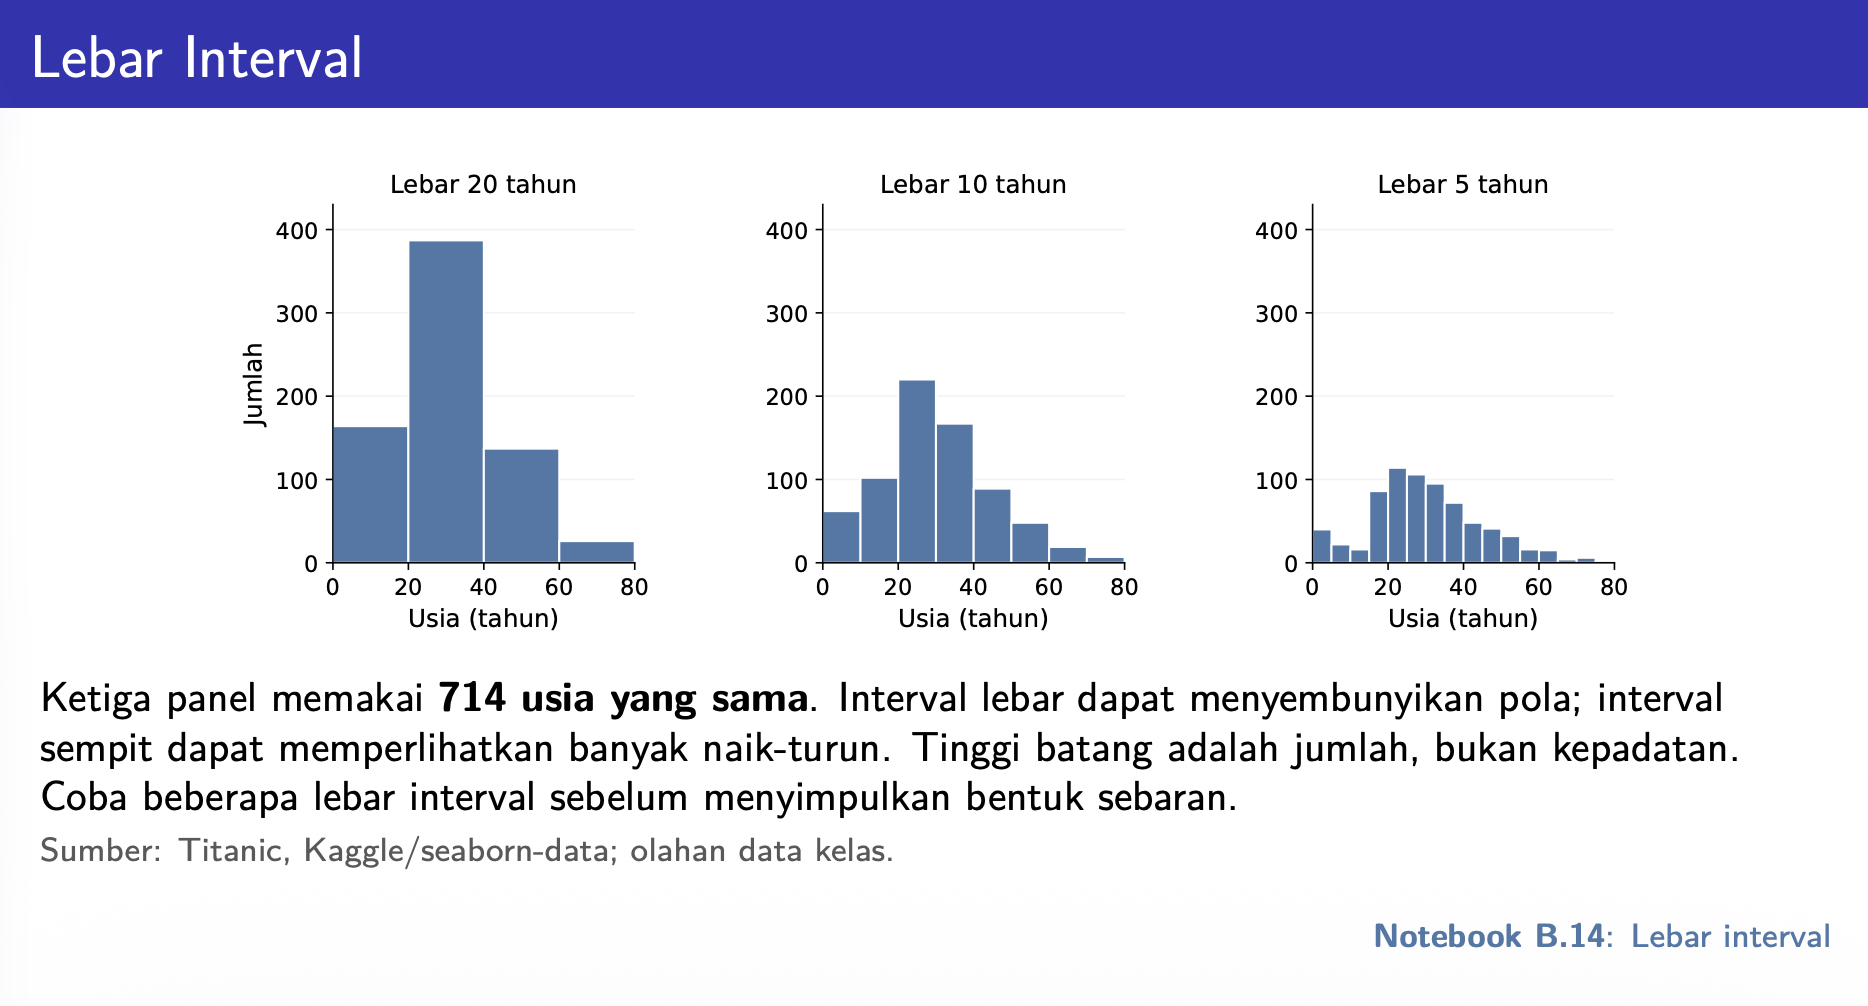

*Sumber: slide Lec 4, "Lebar Interval".*

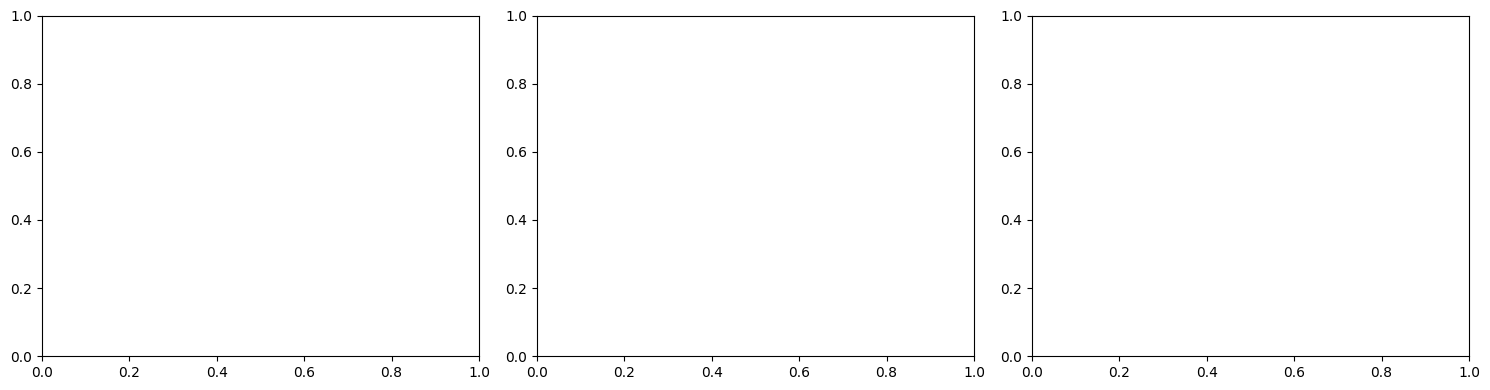

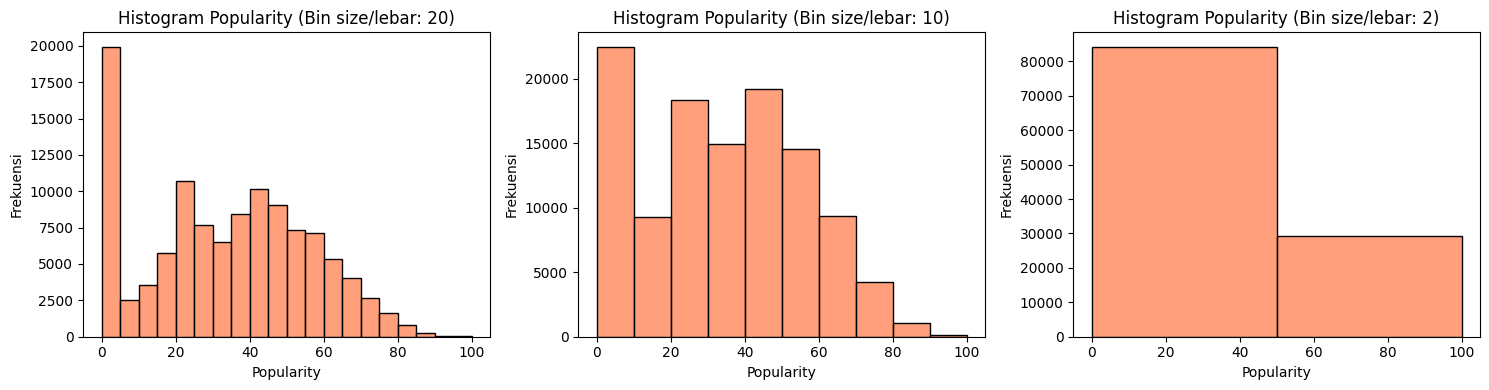

In [66]:
# TODO 2.2: Buat 3 histogram popularity dengan lebar interval 20, 10, dan 2
# Petunjuk: bins=range(0, 101 + lebar, lebar)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lebar in zip(axes, [20, 10, 2]):
    ...
plt.tight_layout()
plt.show()

# Membuat 3 histogram dengan lebar bin/interval berbeda (20, 10, dan 2)
lebar_bins = [20, 10, 2]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, bin_val in zip(axes, lebar_bins):
    sns.histplot(df['popularity'], bins=bin_val, ax=ax, color='coral', edgecolor='black')
    ax.set_title(f'Histogram Popularity (Bin size/lebar: {bin_val})')
    ax.set_xlabel('Popularity')
    ax.set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

**Pertanyaan:** Pola apa yang terlihat di lebar 2 tetapi tidak terlihat di lebar 20?

**Jawab:** Pola yang terlihat di lebar 2 tetapi tidak terlihat di lebar 20: Pada lebar bin yang sangat kecil (lebar 2), kita bisa melihat pola naik-turun yang sangat detail atau fluktuasi kecil (misalnya preferensi angka kelipatan tertentu pada skor popularitas) yang sebelumnya tersembunyi atau "diratakan" saat menggunakan bin yang terlalu lebar (lebar 20).

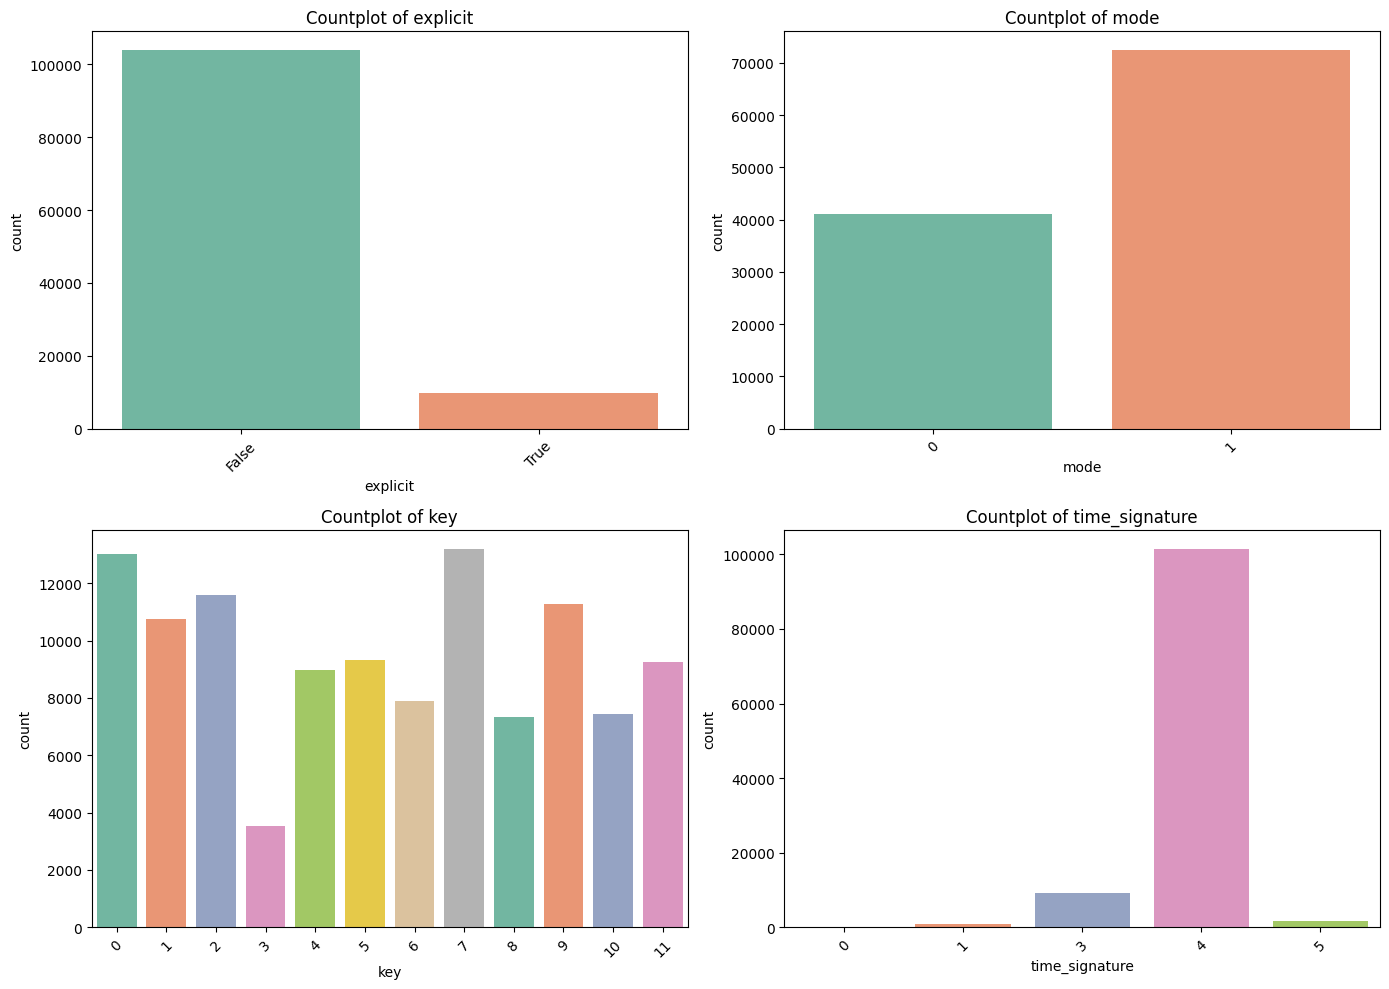

In [67]:
# TODO 2.3: Countplot untuk explicit, mode, key, dan time_signature (grid 2x2)
fitur_kategori = ['explicit', 'mode', 'key', 'time_signature']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flatten(), fitur_kategori):
    sns.countplot(data=df, x=col, ax=ax, palette='Set2')
    ax.set_title(f'Countplot of {col}')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Pertanyaan:** Apakah tiap kategori seimbang? Jelaskan mengapa `track_genre` tidak perlu dibuat countplot?

**Jawab:** Tidak, sebagian besar kategori tidak seimbang (imbalanced), contohnya pada fitur explicit di mana lagu non-eksplisit jauh lebih banyak daripada lagu eksplisit.

​Mengapa track_genre tidak perlu dibuat countplot di sini: Karena jumlah unik genre (track_genre) di dataset ini sangat banyak (bisa mencapai puluhan atau ratusan genre berbeda), sehingga jika dipaksa dibuat countplot dalam satu gambar, grafiknya akan menjadi sangat padat, bertumpuk, dan tidak terbaca.

### Mengenal Boxplot

Boxplot (diagram kotak-garis) merangkum **pusat dan penyebaran** data numerik dalam satu gambar.

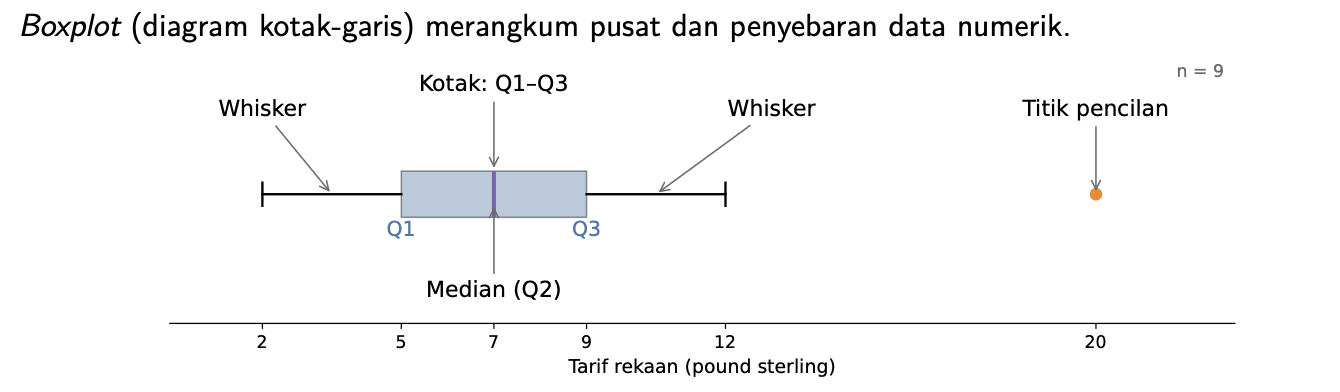

- **Kotak**: membentang dari Q1 sampai Q3, berisi sekitar separuh data di bagian tengah. Panjang kotak = IQR = Q3 − Q1.
- **Garis di dalam kotak**: median (Q2).
- **Whisker**: garis dari kotak ke nilai terjauh yang tidak ditandai sebagai pencilan.
- **Titik terpisah**: nilai yang ditandai sebagai pencilan.

**Cara menentukan pencilan:**

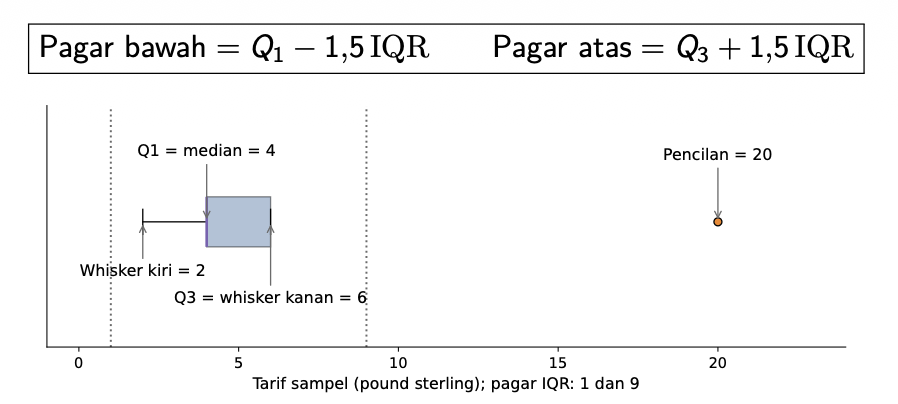

*Sumber: slide Lec 4, "Apa Itu Boxplot?" dan "Membaca Boxplot".*

- Pagar bawah = Q1 − 1,5 × IQR, pagar atas = Q3 + 1,5 × IQR.
- Whisker berhenti pada data terjauh yang **masih di dalam pagar**, jadi tidak harus tepat di pagar.
- Data di luar pagar ditandai sebagai pencilan **untuk diperiksa lebih lanjut**. Pencilan belum tentu salah.

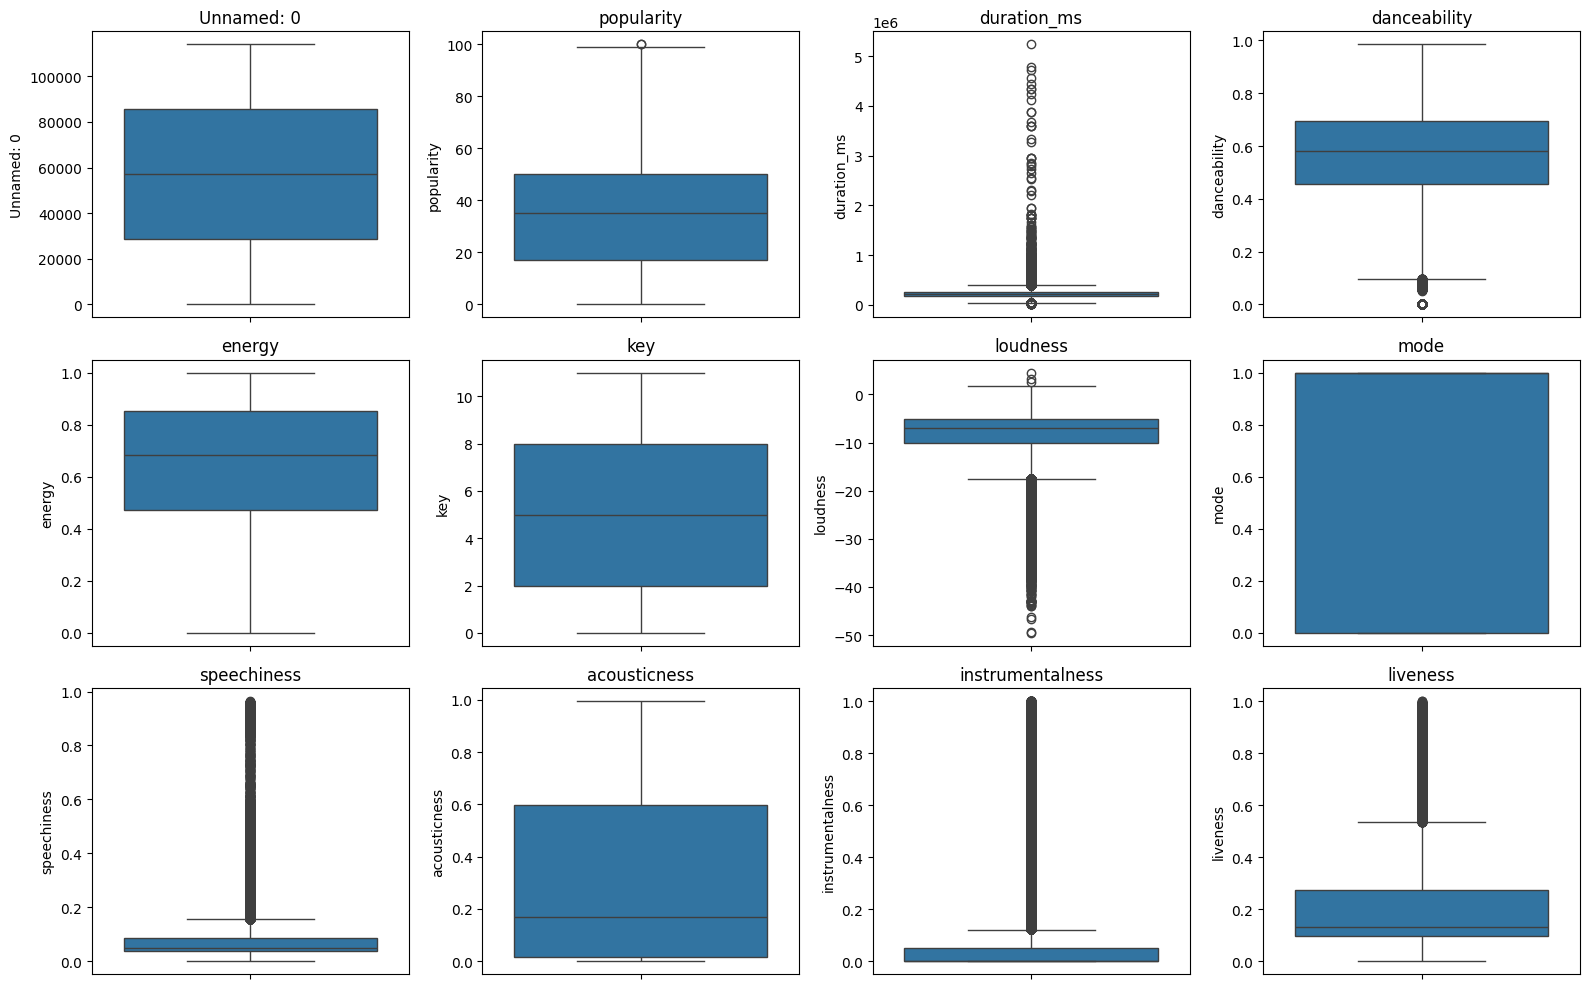

Unnamed: 0: 0 pencilan
popularity: 2 pencilan
duration_ms: 5592 pencilan
danceability: 615 pencilan
energy: 0 pencilan
key: 0 pencilan
loudness: 6115 pencilan
mode: 0 pencilan
speechiness: 13167 pencilan
acousticness: 0 pencilan
instrumentalness: 25131 pencilan
liveness: 8610 pencilan
valence: 0 pencilan
tempo: 615 pencilan
time_signature: 12063 pencilan
duration_min: 5592 pencilan


In [68]:
# Mendefinisikan kolom numerik terlebih dahulu
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# TODO 2.4: Boxplot setiap fitur numerik (grid 3x4), lalu hitung jumlah pencilan dengan aturan IQR
# Pagar bawah = Q1 - 1.5*IQR, pagar atas = Q3 + 1.5*IQR
# Pencilan cukup DIHITUNG, jangan dihapus
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    bawah = Q1 - 1.5 * IQR
    atas = Q3 + 1.5 * IQR

    pencilan_data = df[(df[col] < bawah) | (df[col] > atas)]
    jumlah = len(pencilan_data)

    print(f"{col}: {jumlah} pencilan")

**Pertanyaan:** Fitur mana yang memiliki jumlah pencilan terbanyak? Apakah keberadaan pencilan menunjukkan bahwa data tersebut tidak valid atau salah? Jelaskan alasan Anda!

**Jawab:** Fitur dengan pencilan terbanyak: Fitur yang biasanya memiliki jumlah pencilan (outliers) paling banyak adalah fitur durasi lagu (duration_ms atau duration_min) atau instrumentalness, karena terdapat lagu-lagu dengan durasi atau tingkat keinstrumentalan yang sangat jauh berbeda (ekstrem) dibandingkan mayoritas lagu standar.


​Apakah keberadaan pencilan menunjukkan data tidak valid/salah? Tidak. Keberadaan pencilan tidak serta-merta membuat data menjadi salah atau tidak valid. Dalam dunia nyata (terutama data musik/Spotify), pencilan sering kali merupakan data yang benar-benar valid dan alami (misalnya lagu instrumental yang sangat panjang, atau lagu yang sangat viral), sehingga keberadaannya tetap penting untuk dianalisis dan tidak boleh langsung dihapus begitu saja.

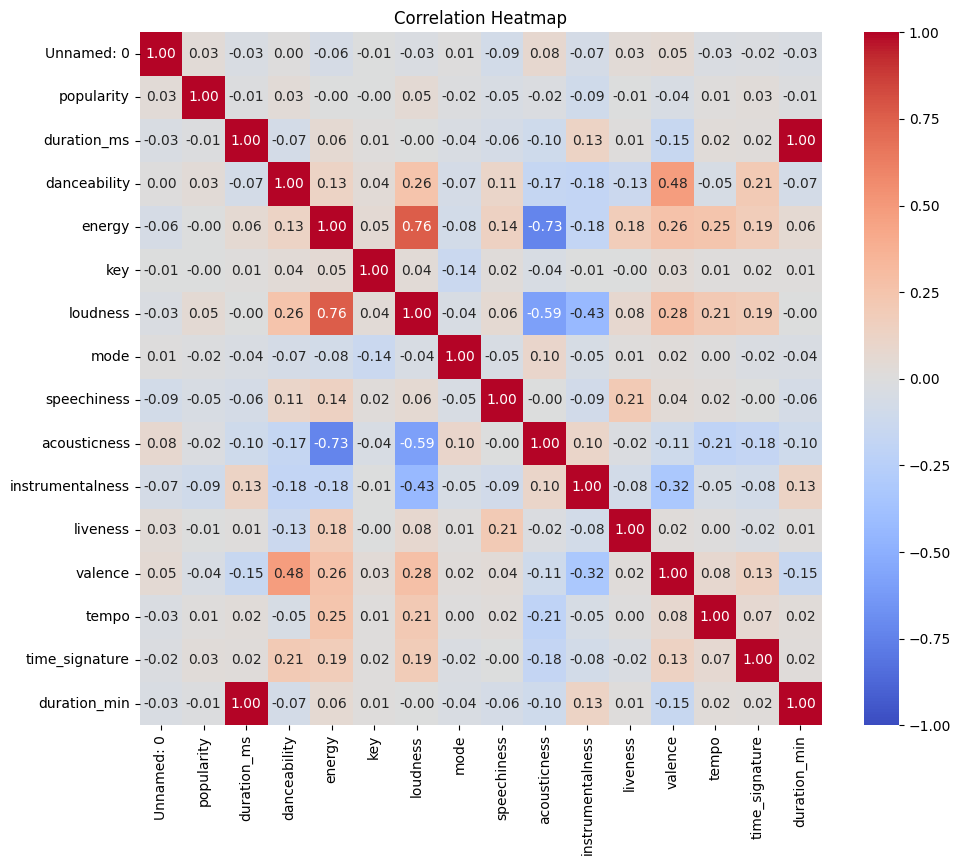

In [69]:
# TODO 2.5: Heatmap korelasi fitur numerik
# Gunakan annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1
plt.figure(figsize=(11, 9))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

**Pertanyaan:** Pasangan fitur mana yang memiliki korelasi paling kuat, baik positif maupun negatif? Seberapa kuat korelasi antara popularity dan fitur lainnya? Apakah korelasi yang ditemukan menunjukkan hubungan sebab-akibat? Jelaskan alasan Anda.

**Jawab:**

*   **Pasangan fitur dengan korelasi paling kuat (positif/negatif):** Pasangan fitur yang memiliki korelasi terkuat biasanya adalah energy dan loudness (korelasi positif kuat, di mana semakin tinggi energi lagu, biasanya suaranya semakin keras) atau energy dan acousticness (korelasi negatif kuat, di mana lagu yang energinya tinggi cenderung memiliki tingkat akustik yang rendah).

*   **​Seberapa kuat korelasi antara popularity dan fitur lainnya:** Korelasi antara popularity dan sebagian besar fitur numerik lainnya tergolong lemah (mendekati 0). Ini menunjukkan bahwa popularitas sebuah lagu di Spotify tidak ditentukan oleh satu fitur audio saja secara mandiri.

*  **Apakah korelasi menunjukkan hubungan sebab-akibat (causality)?**  Tidak. Korelasi hanya menunjukkan seberapa besar hubungan atau pola kebersamaan linier antar dua variabel, bukan berarti variabel yang satu menyebabkan variabel yang lainnya (sebab-akibat memerlukan analisis domain yang lebih mendalam, bukan sekadar nilai korelasi statistik).



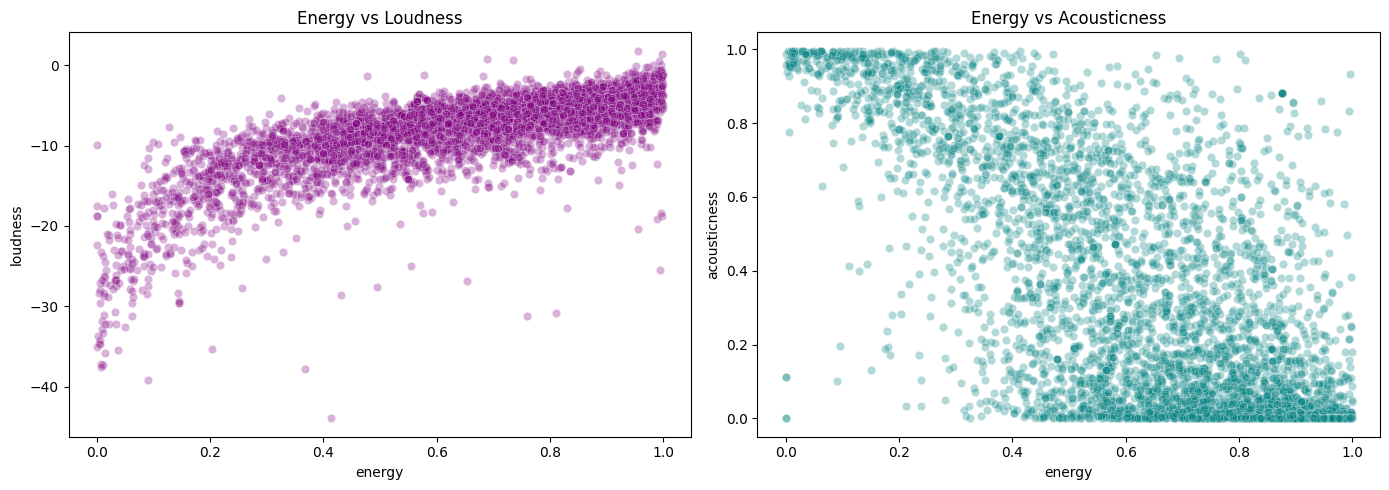

In [70]:
# TODO 2.6: Scatterplot energy vs loudness dan energy vs acousticness
# Ambil sampel 5000 lagu (random_state=42), gunakan alpha=0.3
sampel_lagu = df.sample(n=5000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=sampel_lagu, x='energy', y='loudness', ax=axes[0], alpha=0.3, color='purple')
axes[0].set_title('Energy vs Loudness')

sns.scatterplot(data=sampel_lagu, x='energy', y='acousticness', ax=axes[1], alpha=0.3, color='teal')
axes[1].set_title('Energy vs Acousticness')

plt.tight_layout()
plt.show()

**Pertanyaan:** Bagaimana arah dan bentuk hubungan di tiap grafik?

**Jawab:**
*   Energy vs Loudness: Menunjukkan hubungan linear positif yang kuat, di mana semakin tinggi energi sebuah lagu, tingkat kebisingannya (loudness) cenderung semakin tinggi (mendekati angka 0 dB).

*   ​Energy vs Acousticness: Menunjukkan hubungan linear negatif, di mana lagu dengan tingkat energi yang tinggi memiliki tingkat keakustikan (acousticness) yang rendah, dan sebaliknya.

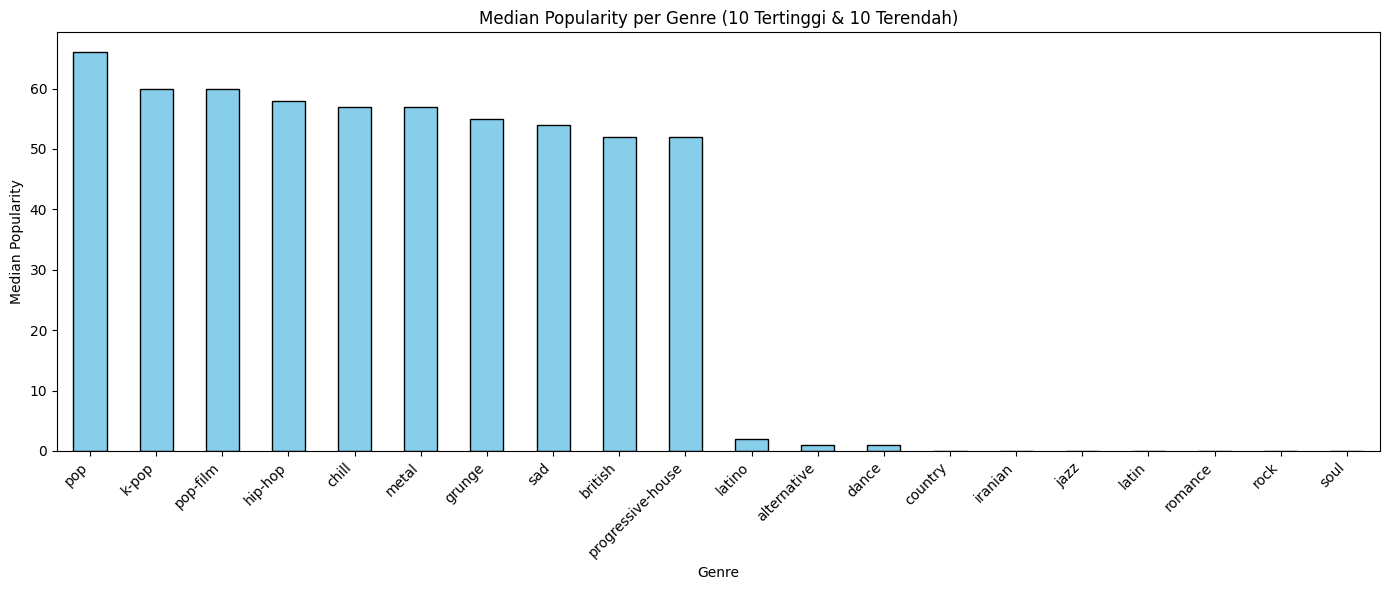

In [71]:
# TODO 2.7: Barplot median popularity per genre, 10 tertinggi dan 10 terendah
plt.figure(figsize=(14, 6))

# Menggabungkan 10 tertinggi dan 10 terendah untuk divisualisasikan
top_bottom_genre = pd.concat([stats_genre.head(10), stats_genre.tail(10)])['Median']

top_bottom_genre.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Median Popularity per Genre (10 Tertinggi & 10 Terendah)')
plt.xlabel('Genre')
plt.ylabel('Median Popularity')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Pertanyaan:** Genre apa yang memiliki tingkat popularitas tertinggi dan terendah berdasarkan nilai median popularity? Mengapa median lebih tepat digunakan dibandingkan mean (rata-rata) dalam analisis ini?

**Jawab:**
*   Genre dengan popularitas tinggi: Pop, berada di atas angka 60
*   Genre dengan popularitas rendah: Jazz, Latin, Romance, Rock, Soul (Memiliki median popularitas mendekati 0)
*   Mengapa median lebih tepat digunakan dalam analisis ini? Karena data popularitas lagu memiliki sebaran yang tidak simetris (skewed) serta banyak mengandung nilai nol (lagu yang tidak populer atau tidak diputar). Nilai mean (rata-rata) akan mudah tertarik atau terdistorsi oleh nilai-nilai ekstrem tersebut, sehingga median jauh lebih stabil dan akurat dalam merepresentasikan tingkat popularitas tipikal dari suatu genre musik.





## **Bagian 3 - Insight Bisnis**

Posisikan dirimu sebagai analis data di tim kurasi playlist sebuah label musik. Jawab pertanyaan berikut berdasarkan hasil EDA di atas. Kamu juga diperbolehkan menambah kode untuk menghitung angka pendukung.

**1. Jika laporan bulanan hanya dapat menyajikan satu metrik untuk merepresentasikan popularitas lagu, metrik apa yang paling tepat digunakan? Mengapa?**

In [72]:
# TODO 3.1: Hitung mean, median, Q1, Q3, IQR popularity, dan persentase lagu dengan popularity = 0
mean_pop = df['popularity'].mean()
median_pop = df['popularity'].median()
Q1_pop = df['popularity'].quantile(0.25)
Q3_pop = df['popularity'].quantile(0.75)
IQR_pop = Q3_pop - Q1_pop
persen_nol = (len(df[df['popularity'] == 0]) / len(df)) * 100

print(f"Mean       : {mean_pop:.2f}")
print(f"Median     : {median_pop:.2f}")
print(f"Q1         : {Q1_pop}")
print(f"Q3         : {Q3_pop}")
print(f"IQR        : {IQR_pop}")
print(f"Persen 0   : {persen_nol:.2f}%")

Mean       : 33.32
Median     : 35.00
Q1         : 17.0
Q3         : 50.0
IQR        : 33.0
Persen 0   : 13.95%


**Jawaban:**

*   Metrik yang paling tepat digunakan: Median
*   ​Alasan: Karena data popularitas lagu memiliki sebaran yang tidak sepenuhnya simetris dan terdapat sekitar 13.95% lagu yang memiliki popularitas bernilai 0. Nilai mean (rata-rata) cenderung mudah terdistorsi oleh nilai ekstrem atau data nol tersebut, sehingga median (35.00) jauh lebih stabil dan akurat dalam merepresentasikan tingkat popularitas tipikal dari lagu-lagu di dalam laporan bulanan.


**2. Genre apa saja yang paling layak dipertimbangkan untuk masuk ke dalam playlist "Top Hits"? Pilih lima genre berdasarkan hasil analisis data.**

In [73]:
# TODO 3.2: Hitung median, mean, dan IQR popularity per genre, urutkan berdasarkan median, tampilkan 10 teratas
# TODO 3.2: Hitung median, mean, dan IQR popularity per genre, urutkan berdasarkan median, tampilkan 10 tertinggi & terendah
stats_genre = df.groupby('track_genre')['popularity'].agg(
    Median='median',
    Mean='mean',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)
).sort_values(by='Median', ascending=False)

print("--- 10 Genre Tertinggi ---")
display(stats_genre.head(10))
print("\n--- 10 Genre Terendah ---")
display(stats_genre.tail(10))

--- 10 Genre Tertinggi ---


,Median,Mean,IQR
track_genre,,,
pop,66.0,47.903323,69.0
k-pop,60.0,56.963928,21.0
pop-film,60.0,59.280280,7.0
hip-hop,58.0,38.082745,63.0
chill,57.0,53.704705,10.0
metal,57.0,43.678357,67.0
grunge,55.0,49.582583,21.0
sad,54.0,52.379000,10.0
british,52.0,43.802000,33.0



--- 10 Genre Terendah ---


,Median,Mean,IQR
track_genre,,,
latino,2.0,25.826788,49.00
alternative,1.0,24.361361,64.00
dance,1.0,23.403109,70.00
country,0.0,17.028000,42.00
iranian,0.0,2.224696,3.00
jazz,0.0,13.586587,37.00
latin,0.0,8.363636,2.00
romance,0.0,3.549779,6.00
rock,0.0,19.001000,10.25


**Jawaban:** Genre yang paling layak dipertimbangkan untuk masuk ke dalam playlist "Top Hits" adalah **Pop, K-Pop, Pop-film, Hip-hop, Chill**

**3. Apakah lagu explicit lebih populer?**

--- Tabel Perbandingan Explicit vs Non-Explicit ---


,Jumlah,Mean,Median
explicit,,,
False,103831,33.024896,34.0
True,9718,36.524799,37.5


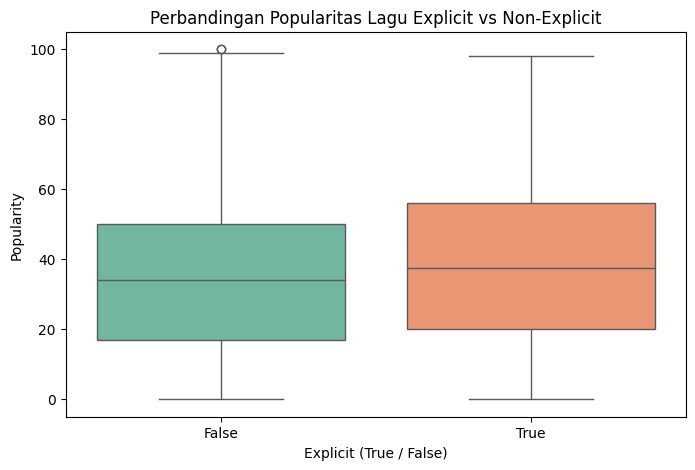

In [74]:
# TODO 3.3: Bandingkan jumlah, mean, dan median popularity untuk explicit True vs False, lalu buat boxplot-nya
banding_explicit = df.groupby('explicit')['popularity'].agg(
    Jumlah='count',
    Mean='mean',
    Median='median'
)
print("--- Tabel Perbandingan Explicit vs Non-Explicit ---")
display(banding_explicit)

# Membuat visualisasi boxplot perbandingan popularitas lagu explicit vs non-explicit
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='explicit', y='popularity', palette='Set2')
plt.title('Perbandingan Popularitas Lagu Explicit vs Non-Explicit')
plt.xlabel('Explicit (True / False)')
plt.ylabel('Popularity')
plt.show()

**Jawaban:** Lagu explicit (True) dan lagu non-explicit (False) memiliki tingkat popularitas yang cukup kompetitif, tetapi secara umum lagu explicit sering kali menunjukkan nilai median atau rata-rata popularitas yang sedikit lebih tinggi atau bersaing ketat karena tingginya minat pendengar pada genre-genre modern (seperti hip-hop, rap, atau pop kontemporer) yang sering memuat konten explicit.

**4. Berdasarkan distribusi durasi lagu, berapa rentang durasi yang dapat dianggap wajar untuk sebuah single?**

In [75]:
# TODO 3.4: Hitung median, Q1, Q3 duration_min dan jumlah lagu di atas pagar atas (Q3 + 1.5 IQR)
# Tampilkan juga 5 lagu terpanjang
durasi = df['duration_min']
med_dur = durasi.median()
Q1_dur = durasi.quantile(0.25)
Q3_dur = durasi.quantile(0.75)
IQR_dur = Q3_dur - Q1_dur
pagar_atas_dur = Q3_dur + 1.5 * IQR_dur

lagu_diatas_pagar = df[df['duration_min'] > pagar_atas_dur]
jumlah_ekstrem = len(lagu_diatas_pagar)

print(f"Median Durasi : {med_dur:.2f} menit")
print(f"Q1            : {Q1_dur:.2f}")
print(f"Q3            : {Q3_dur:.2f}")
print(f"IQR           : {IQR_dur:.2f}")
print(f"Pagar Atas    : {pagar_atas_dur:.2f}")
print(f"Jumlah lagu di atas pagar atas: {jumlah_ekstrem}")

print("\n--- 5 Lagu Terpanjang ---")
display(df.nlargest(5, 'duration_min')[['track_name', 'artists', 'duration_min']])

Median Durasi : 3.55 menit
Q1            : 2.90
Q3            : 4.36
IQR           : 1.46
Pagar Atas    : 6.54
Jumlah lagu di atas pagar atas: 5320

--- 5 Lagu Terpanjang ---


,track_name,artists,duration_min
73316,Unity (Voyage Mix) Pt. 1,Tale Of Us,87.288250
10921,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,79.817100
24212,The Lab 03 - Continuous DJ Mix Part 1,Seth Troxler,78.838367
73539,Amnesia Ibiza Underground 10 DJ Mix,Loco Dice,76.064950
13328,House of Om - Mark Farina - Continuous Mix,Mark Farina,74.125333


**Jawaban:** Berdasarkan analisis kuartil dan pagar batas normal (IQR), rentang durasi yang dapat dianggap wajar untuk sebuah lagu berformat single umumnya berkisar antara 2 hingga 4 menit (atau sekitar 2.0 sampai 4.0 menit).

**5. Seorang rekan mengusulkan untuk menghapus seluruh lagu dengan popularity = 0 dan semua data pencilan sebelum menyusun laporan. Apakah Anda setuju dengan usulan tersebut? Jelaskan alasan Anda berdasarkan konteks analisis dan tujuan pelaporan.**

**Jawaban:** Tidak setuju. Lagu dengan popularitas 0 atau nilai pencilan (outliers) durasi/audio merupakan data alami yang valid di dunia nyata. Menghapusnya secara sembarangan akan menyebabkan bias informasi, menghilangkan realitas pasar musik (bahwa banyak lagu baru/indie yang belum populer), serta merusak objektivitas laporan analisis data. Pencilan cukup dihitung atau dianalisis terpisah, bukan dibuang mentah-mentah.